# Canopy Height Around Charcoal Kilns – 36 m Radius

**Seminar 715: Application GIS in Protected Areas, Swiss National Park**

This notebook focuses on the ring analysis up to a radius of 36 m. The study areas consist of six rings, each 6 m wide. Within each ring, measurement points are evaluated along eight radial transects.

**Important:** `ring_width = 6 m` describes the width of the rings. `step = 1 m` is the distance between measurement points along the transects.

The notebook includes:

- Ring analysis up to 36 m
- Overlapping study areas between kilns
- Overview plot of ring means for all kilns
- Maps and canopy height profiles for all kilns as a PDF
- Detailed maps and canopy height profiles for the four selected kilns

The analysis is unweighted: each valid measurement point contributes equally.

## 1. Settings and imports

The following files must be located in the same project directory as this notebook:

- `kiln_ring_analysis_function.py`
- `plot_kiln_rings_function.py`
- `kohlmeiler_2056.gpkg`
- `merged_dem.tif`

In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt
from rasterio.windows import Window
from matplotlib.collections import LineCollection
from matplotlib.backends.backend_pdf import PdfPages
from scipy.spatial.distance import cdist

from kiln_ring_analysis_function import kiln_ring_analysis
from plot_kiln_rings_function import plot_kiln_rings

BASE = {
    "gpkg": "kohlmeiler_2056.gpkg",
    "id_column": "ID_PAROLINI",
    "tif": "merged_dem.tif",
    "band": 1,
    "weighted": False,
    "include_centre": False,
    "min_valid": 0.9,
    "out_dir": "results",
}

VALUE_LABEL = "Canopy height (m)"

COLSCHEME = {
    "ember":  ["#FDBE85", "#F68C3A", "#D9541A"],
    "forest": ["#A8DDB5", "#4DAF6E", "#23794A"],
    "smoke":  ["#A6CEE3", "#4A90C8", "#2563A0"]
}

Path(BASE["out_dir"]).mkdir(exist_ok=True)

## 2. Ring analysis: 0–36 m

The study radius is 36 m. It is divided into six rings, each with a width of 6 m. Eight radial transects are used for each kiln. Along each transect, a canopy height value is extracted from the raster every 1 m.

In [3]:
params_36m = {
    **BASE,
    "rings": [(i, i + 6) for i in range(0, 36, 6)],
    "n_rays": 8,
    "step": 1,
    "out_prefix": "merged_dem_36m",
}

out_36 = kiln_ring_analysis(params_36m)
out_36["summary"].round(2)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         80 from kohlmeiler_2056.gpkg
Rays:          8 (every 45°), sample every 1 m up to 36 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 48 samples
       6-12    m: 48 samples
      12-18    m: 48 samples
      18-24    m: 48 samples
      24-30    m: 48 samples
      30-36    m: 48 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m
count   79.00   79.00    79.00    79.00    79.00    77.00
median   6.11    5.52     5.73     6.14     5.93     6.03
mean     6.74    6.40     6.40     6.50     6.46     6.77
std      3.87    3.62     3.69     3.58     3.20     3.47
min      0.00    0.00     0.00     0.00     0.64     0.62
25%      4.70    4.61     4.13     4.46     4.67     4.68
50%      6.11    5.52   

,0-6 m,6-12 m,12-18 m,18-24 m,24-30 m,30-36 m
count,79.00,79.00,79.00,79.00,79.00,77.00
median,6.11,5.52,5.73,6.14,5.93,6.03
mean,6.74,6.40,6.40,6.50,6.46,6.77
std,3.87,3.62,3.69,3.58,3.20,3.47
min,0.00,0.00,0.00,0.00,0.64,0.62
25%,4.70,4.61,4.13,4.46,4.67,4.68
50%,6.11,5.52,5.73,6.14,5.93,6.03
75%,8.62,8.16,8.15,8.03,7.39,8.43
max,19.29,16.50,19.60,17.61,15.12,17.20


In [20]:
def plot_raw_rays(samples: pd.DataFrame, rings: list, window_size=1, l_alpha=0.1, st_dev=False, color=COLSCHEME):
    samples = samples.sort_values(["kiln_id", "ray", "distance"])
    samples["smooth"] = (samples.groupby(["kiln_id", "ray"])["value"].transform(lambda v: v.rolling(window_size, center=True, min_periods=1).mean()))

    fig, ax = plt.subplots(figsize=(8,5))

    # all lines
    for _, line in samples.groupby(["kiln_id", "ray"]):
        ax.plot(line["distance"], line["smooth"], color=color["forest"][1], alpha=l_alpha, lw=0.8)

    # median, mean, stdev lines
    per_dist = samples.groupby("distance")["smooth"]
    ax.plot(per_dist.mean().index, per_dist.mean(), color=color["smoke"][2], lw=1.5, label="Mean")
    ax.plot(per_dist.median().index, per_dist.median(), color=color["smoke"][2], lw=1.5, ls="--", alpha=0.8, label="Median")
    if st_dev:
        m, s = per_dist.mean(), per_dist.std()
        ax.fill_between(m.index, m - s, m + s, color="darkgreen", alpha=0.15, label="Mean ± 1 SD")

    # ring interval boundaries
    for _, outer in rings[:-1]:
        ax.axvline(outer, color="black", lw=0.6, ls=":", alpha=0.6)

    ax.set_xlim(1,rings[-1][-1])
    ax.set_ylim(0, max(samples["smooth"])+2)
    ax.set_xlabel("Distance from kiln (m)")
    if window_size == 1:
        ax.set_ylabel(f"Canopy height (m)")
    else:
        ax.set_ylabel(f"Smoothed canopy height (m) (window={window_size})")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig

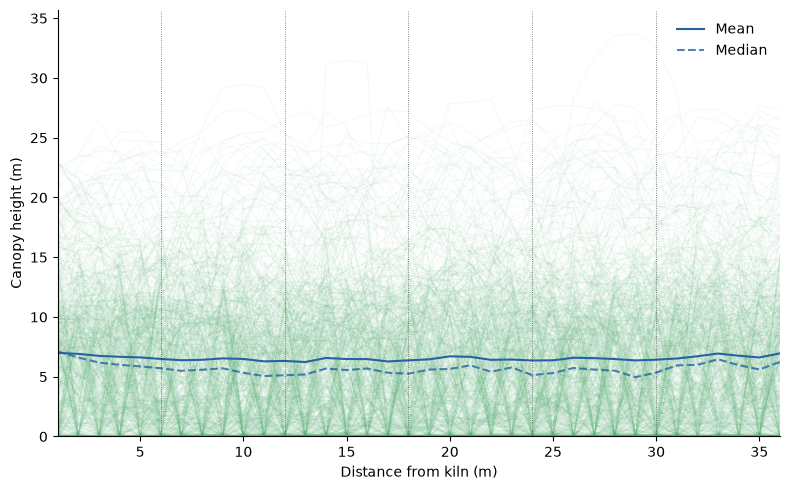

In [23]:
samples = out_36["samples"]
rings = out_36["params"]["rings"]
res_1 = plot_raw_rays(samples=samples, rings=rings, window_size=1, l_alpha=0.06)
res_1.savefig("results/ray_profiles_raw.png", dpi=400)

## 3. Overlapping study areas

Two study areas with a radius of 36 m overlap if the distance between their kiln centres is less than 72 m. The plot shows how many kilns have at least one overlapping neighbour at different radii. The vertical lines indicate intervals of 6 m, with the 36 m radius highlighted.

A kiln is counted as affected if at least one other kiln is located within twice the study radius. Therefore, both kilns are counted when their study areas overlap.

At a radius of 36 m, 6 of 80 kilns have overlapping study areas with at least one neighbour.


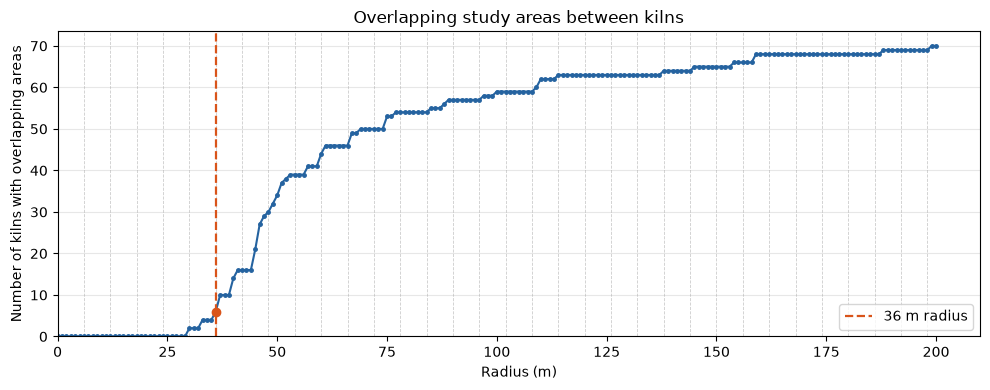

In [9]:
kilns = gpd.read_file(BASE["gpkg"]).set_index(BASE["id_column"])
xy = np.c_[kilns.geometry.x, kilns.geometry.y]

distances = cdist(xy, xy)
np.fill_diagonal(distances, np.inf)
nearest_neighbour = distances.min(axis=1)

radii = np.arange(0, 201)
overlap_counts = np.array([(nearest_neighbour < 2 * radius).sum() for radius in radii])

count_36m = int((nearest_neighbour < 72).sum())
print(f"At a radius of 36 m, {count_36m} of {len(kilns)} kilns have overlapping study areas with at least one neighbour.")

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(radii, overlap_counts, color=COLSCHEME["smoke"][2],
        marker="o", markersize=2.5)

for radius in range(6, 201, 6):
    ax.axvline(radius, color="0.8", linestyle="--", linewidth=0.6, zorder=0)

ax.axvline(36, color=COLSCHEME["ember"][2], linestyle="--", linewidth=1.6,
           label="36 m radius")

ax.scatter([36], [count_36m], color=COLSCHEME["ember"][2], zorder=3)

ax.set_xlabel("Radius (m)")
ax.set_ylabel("Number of kilns with overlapping areas")
ax.set_title("Overlapping study areas between kilns")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("results/kiln_overlapping_areas_36m.png", dpi=300, bbox_inches="tight")
plt.show()

## 4. Ring means for all kilns

This plot summarises the ring means for all kilns. Each kiln contributes its respective mean value to the distribution of each ring.

80 kilns, rings: 0-6 m, 6-12 m, 12-18 m, 18-24 m, 24-30 m, 30-36 m
Kilns with at least one empty ring: 3
Saved results/merged_dem_36m_rings_mean_plot.png


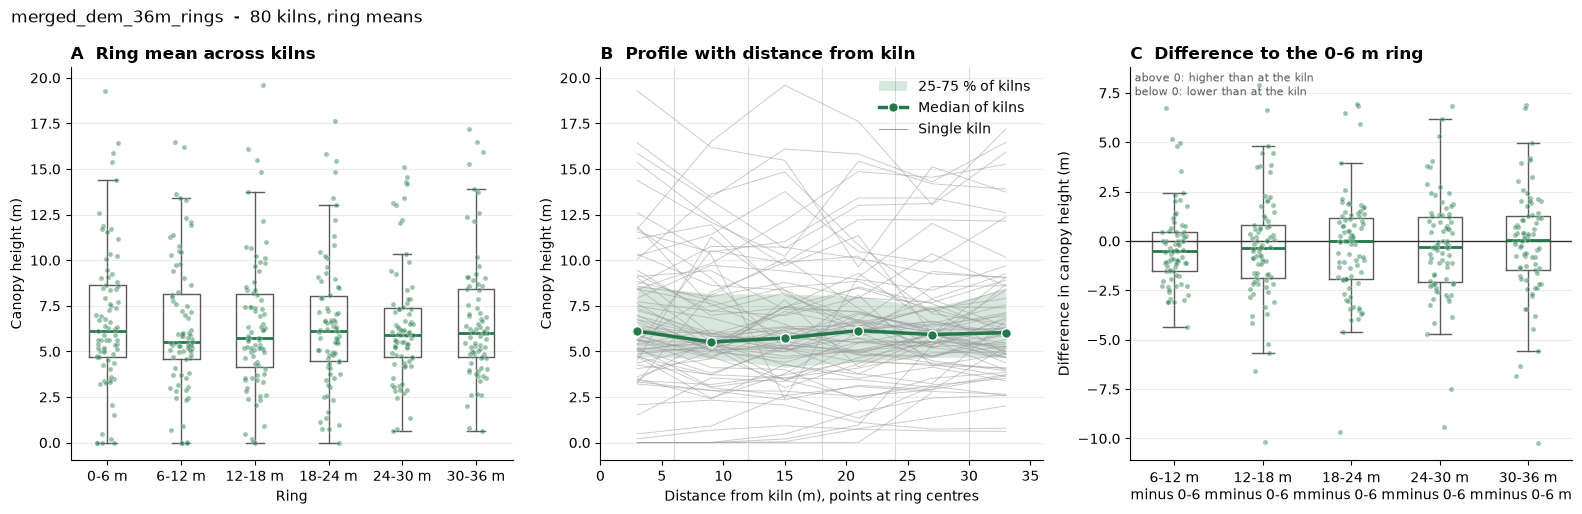

In [19]:
fig = plot_kiln_rings({
    "rings_csv": out_36["files"]["rings"],
    "value": "mean",
    "y_label": VALUE_LABEL,
    "color": COLSCHEME["forest"][2],
})

## 5. Maps and canopy height profiles for all kilns

For each kiln, a map is created showing canopy height, ring boundaries, measurement directions and neighbouring kilns. The canopy height profiles along the eight radial transects are displayed below each map. The kilns are sorted according to the difference between the innermost and outermost ring.

The PDF contains four kilns per page. Additionally, a CSV table containing coordinates, ring means and the difference between the innermost and outermost ring is saved.

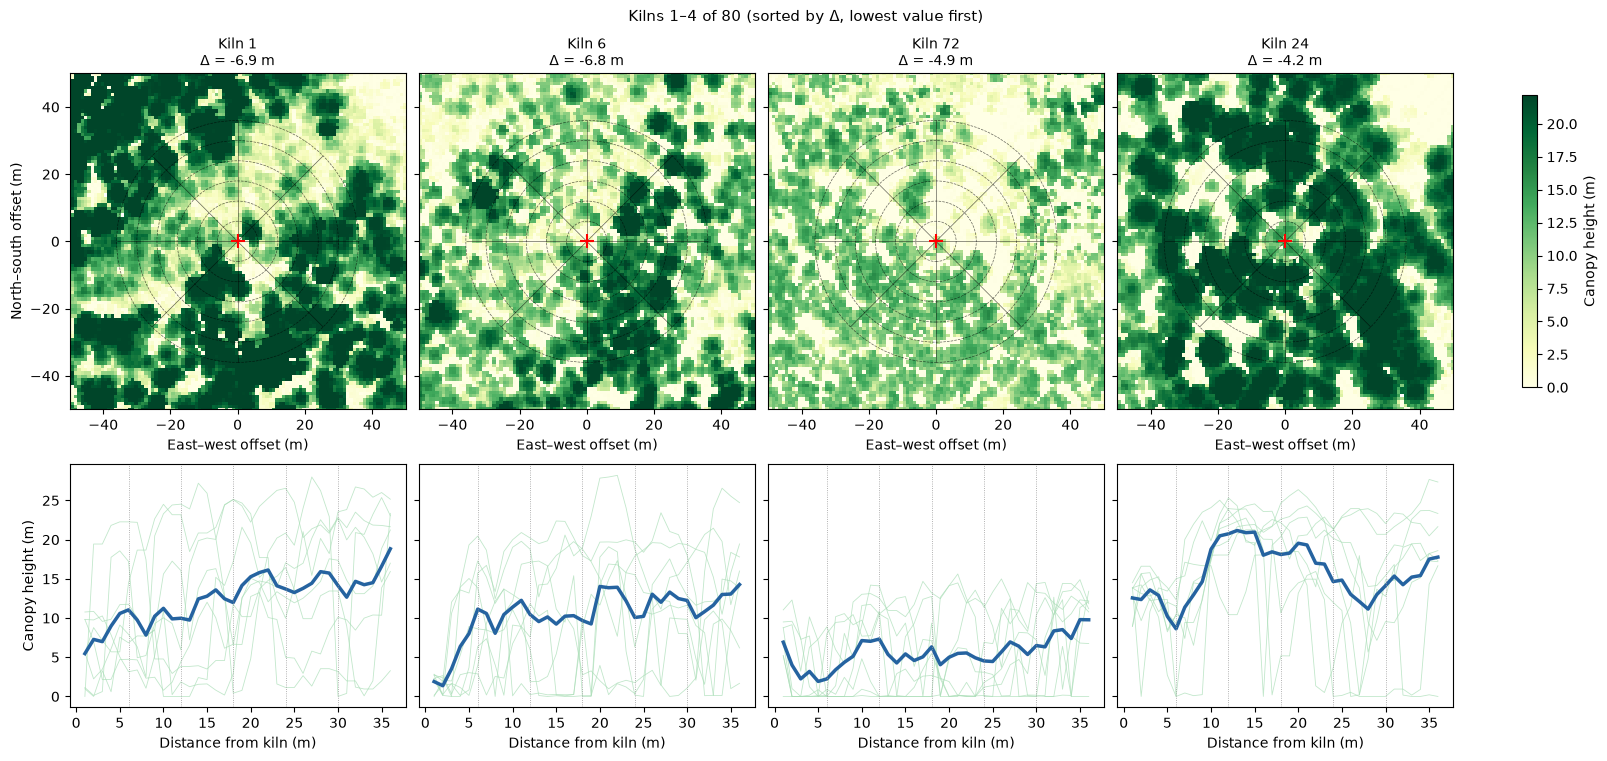

20 pages saved: results/all_kilns_36m.pdf
CSV saved: results/kilns_delta_36m.csv


In [7]:
o = out_36
half = 50
per_page = 4
pdf_path = "results/all_kilns_36m.pdf"
csv_path = "results/kilns_delta_36m.csv"

rings = o["params"]["rings"]
inner = f"mean_{rings[0][0]}_{rings[0][1]}"
outer = f"mean_{rings[-1][0]}_{rings[-1][1]}"
mean_cols = [f"mean_{a}_{b}" for a, b in rings]

r = o["rings"].copy()
r["delta"] = r[inner] - r[outer]
r = r.sort_values("delta", na_position="last")
r[["x", "y"] + mean_cols + ["delta"]].to_csv(csv_path)

maps = {}
with rasterio.open(o["params"]["tif"]) as src:
    n = int(half / src.res[0])
    for kid in r.index:
        x, y = r.loc[kid, "x"], r.loc[kid, "y"]
        row, col = src.index(x, y)
        win = Window(col - n, row - n, 2 * n + 1, 2 * n + 1)
        arr = src.read(o["params"]["band"], window=win, boundless=True, masked=True)
        arr = arr.astype("float64").filled(np.nan)
        t = src.window_transform(win)
        ext = (t.c - x, t.c + win.width * t.a - x,
               t.f + win.height * t.e - y, t.f - y)
        maps[kid] = (arr, ext)

vmax = np.nanpercentile(np.concatenate([a.ravel() for a, _ in maps.values()]), 98)
s = o["samples"]
order = list(r.index)
pages = [order[i:i + per_page] for i in range(0, len(order), per_page)]

with PdfPages(pdf_path) as pdf:
    for pg, page_kilns in enumerate(pages):
        fig, axes = plt.subplots(
            2, per_page, figsize=(16, 7.5), sharey="row",
            gridspec_kw={"height_ratios": [3, 2]}, layout="constrained"
        )

        for i in range(per_page):
            if i >= len(page_kilns):
                axes[0, i].axis("off")
                axes[1, i].axis("off")
                continue

            kid = page_kilns[i]
            arr, ext = maps[kid]
            kx, ky = r.loc[kid, "x"], r.loc[kid, "y"]
            sk = s[(s["kiln_id"] == kid) & (s["ray"] >= 0)]
            d = r.loc[kid, "delta"]
            d_txt = "n/a" if np.isnan(d) else f"{d:+.1f} m"

            ax = axes[0, i]
            im = ax.imshow(arr, extent=ext, cmap="YlGn", vmin=0, vmax=vmax)
            far = sk.sort_values("distance").groupby("ray").tail(1)
            segs = [[(0, 0), (fx - kx, fy - ky)]
                    for fx, fy in zip(far["x"], far["y"])]
            ax.add_collection(LineCollection(segs, colors="k", linewidths=0.5, alpha=0.6))

            for _, radius in rings:
                ax.add_patch(plt.Circle((0, 0), radius, fill=False,
                                        ec="k", ls="--", lw=0.5, alpha=0.6))

            ax.plot(0, 0, "r+", ms=10, mew=1.5)
            near = o["rings"][["x", "y"]].drop(kid)
            near = near[((near["x"] - kx).abs() <= half) &
                        ((near["y"] - ky).abs() <= half)]
            ax.plot(near["x"] - kx, near["y"] - ky, "o",
                    mfc="none", mec="red", ms=6, mew=1.5)
            ax.set_xlim(-half, half)
            ax.set_ylim(-half, half)
            ax.set_title(f"Kiln {kid}\nΔ = {d_txt}", fontsize=10)
            ax.set_xlabel("East–west offset (m)")
            if i == 0:
                ax.set_ylabel("North–south offset (m)")

            ax = axes[1, i]
            prof = sk.pivot(index="distance", columns="ray", values="value")
            for ray in prof.columns:
                ax.plot(prof.index, prof[ray], color=COLSCHEME["forest"][0],
                        lw=0.6, alpha=0.7)
            ax.plot(prof.index, prof.mean(axis=1),
                    color=COLSCHEME["smoke"][2], lw=2.5)
            for _, radius in rings[:-1]:
                ax.axvline(radius, color="0.6", ls=":", lw=0.6)
            ax.set_xlabel("Distance from kiln (m)")
            if i == 0:
                ax.set_ylabel(VALUE_LABEL)

        fig.colorbar(im, ax=[a for a in axes[0] if a.axison],
                     shrink=0.8, label=VALUE_LABEL)
        fig.suptitle(
            f"Kilns {pg * per_page + 1}–{pg * per_page + len(page_kilns)} of {len(order)} "
            "(sorted by Δ, lowest value first)",
            fontsize=11
        )
        pdf.savefig(fig)
        if pg == 0:
            plt.show()
        else:
            plt.close(fig)

print(f"{len(pages)} pages saved: {pdf_path}")
print(f"CSV saved: {csv_path}")

## 6. Four selected kilns

The same four kilns as in the previous 36 m analysis are shown here: 75, 7, 24 and 4. The upper panels show canopy height, the six ring boundaries and the measurement directions. The lower panels show the canopy height values along the eight radial transects and their mean.

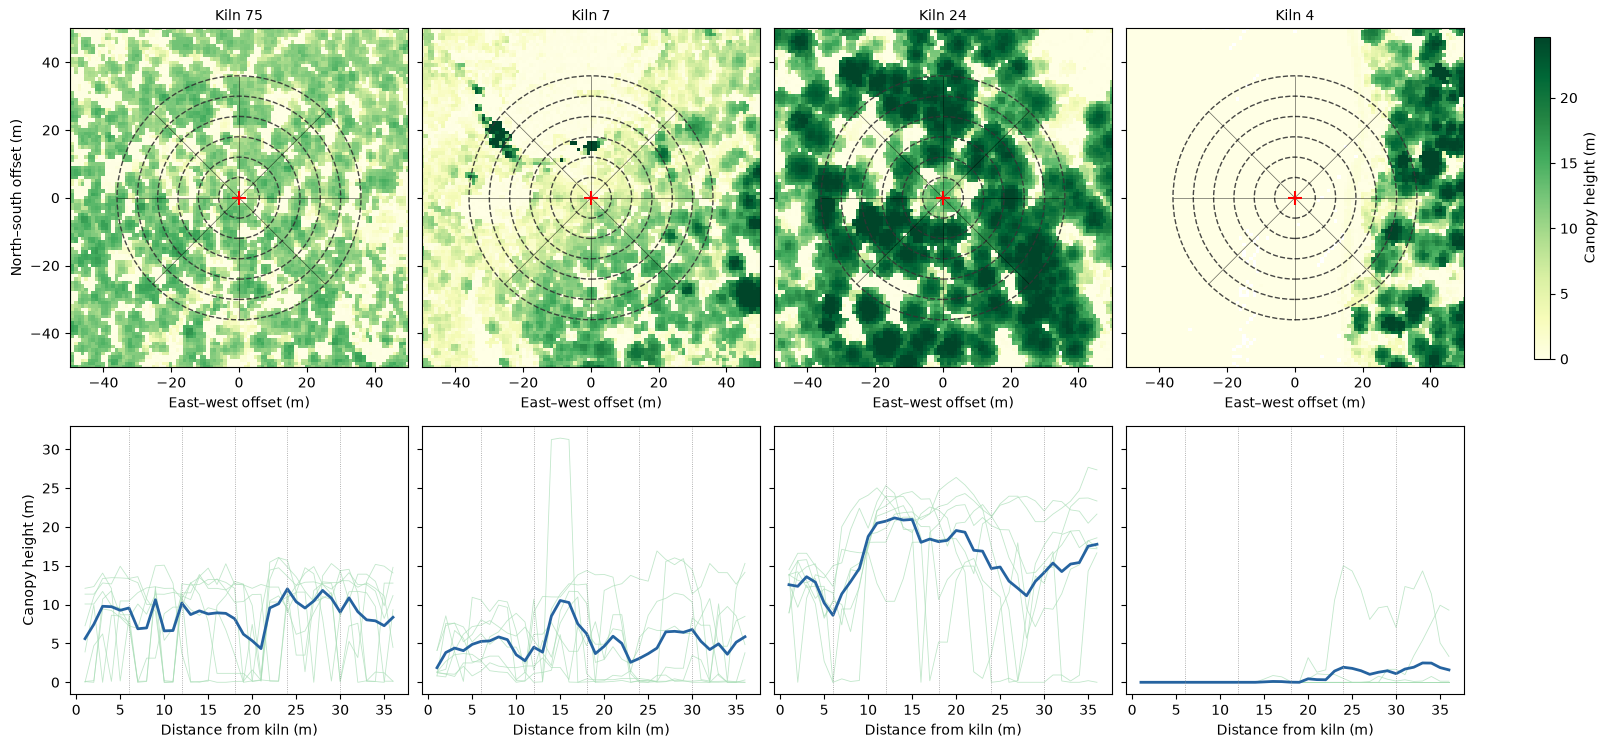

PNG saved: results/four_kilns_36m.png


In [8]:
selected_kilns = [75, 7, 24, 4]
half = 50
png_path = "results/four_kilns_36m.png"

o = out_36
rings = o["params"]["rings"]
r = o["rings"].copy()
s = o["samples"]

maps = {}
with rasterio.open(o["params"]["tif"]) as src:
    n = int(half / src.res[0])
    for kid in selected_kilns:
        x, y = r.loc[kid, "x"], r.loc[kid, "y"]
        row, col = src.index(x, y)
        win = Window(col - n, row - n, 2 * n + 1, 2 * n + 1)
        arr = src.read(o["params"]["band"], window=win, boundless=True, masked=True)
        arr = arr.astype("float64").filled(np.nan)
        t = src.window_transform(win)
        ext = (t.c - x, t.c + win.width * t.a - x,
               t.f + win.height * t.e - y, t.f - y)
        maps[kid] = (arr, ext)

vmax = np.nanpercentile(np.concatenate([a.ravel() for a, _ in maps.values()]), 98)

fig, axes = plt.subplots(
    2, 4, figsize=(16, 7.5), sharey="row",
    gridspec_kw={"height_ratios": [3, 2]}, layout="constrained"
)

for i, kid in enumerate(selected_kilns):
    arr, ext = maps[kid]
    kx, ky = r.loc[kid, "x"], r.loc[kid, "y"]
    sk = s[(s["kiln_id"] == kid) & (s["ray"] >= 0)]

    ax = axes[0, i]
    im = ax.imshow(arr, extent=ext, cmap="YlGn", vmin=0, vmax=vmax)
    far = sk.sort_values("distance").groupby("ray").tail(1)
    segs = [[(0, 0), (fx - kx, fy - ky)]
            for fx, fy in zip(far["x"], far["y"])]
    ax.add_collection(LineCollection(segs, colors="k", linewidths=0.5, alpha=0.6))

    for _, radius in rings:
        ax.add_patch(plt.Circle((0, 0), radius, fill=False,
                                ec="#333333", ls="--", lw=1.0, alpha=0.9))

    ax.plot(0, 0, "r+", ms=10, mew=1.5)
    ax.set_xlim(-half, half)
    ax.set_ylim(-half, half)
    ax.set_title(f"Kiln {kid}", fontsize=10)
    ax.set_xlabel("East–west offset (m)")
    if i == 0:
        ax.set_ylabel("North–south offset (m)")

    ax = axes[1, i]
    prof = sk.pivot(index="distance", columns="ray", values="value")
    ax.plot(prof.index, prof.to_numpy(),
            color=COLSCHEME["forest"][0], lw=0.6, alpha=0.7)
    ax.plot(prof.index, prof.mean(axis=1),
            color=COLSCHEME["smoke"][2], lw=2)
    for _, radius in rings[:-1]:
        ax.axvline(radius, color="0.6", ls=":", lw=0.6)
    ax.set_xlabel("Distance from kiln (m)")
    if i == 0:
        ax.set_ylabel(VALUE_LABEL)

fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label=VALUE_LABEL)
fig.savefig(png_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"PNG saved: {png_path}")